# De 1.000 reseñas a dos agrupamientos: el efecto de retirar 13 comentarios

Esta libreta desarrolla **«Del conjunto inicial a los temas obtenidos»**. A la izquierda seguimos el **modelo base**; a la derecha, la **alternativa**. Queremos ver qué textos retiró el filtro, dónde estaban en el agrupamiento base y cómo se redistribuyen los **987 comentarios comunes** al volver a agrupar.

Recorrido: muestra y embeddings → decisiones de relevancia y 13 textos completos → ejecución de ambos pipelines → verificación frente al reporte → tamaños y cobertura → exclusión sin reajuste frente a nuevo agrupamiento → cruces por identificador → ejemplos de fragmentación → sentimiento, palabras clave e interpretación.

La corrida nueva queda en `data/experiments/julaug-2026-paso-a-paso`; no reemplaza la del reporte. Se ejecutan nuevamente BERTopic, sentimiento y KeyBERTInspired + MMR mediante el productor existente. Los datos preparados, embeddings MiniLM y reducciones UMAP idénticas se reutilizan con verificación de hashes. El filtro ya entrenado vuelve a predecir al preparar la muestra. No se recolectan datos ni se entrenan clasificadores. Las respuestas LLM se reutilizan **solo si coincide la solicitud completa**. Si los pesos cambian en decimales pequeños, se ejecutan las solicitudes faltantes de la nueva corrida cuando se habilita explícitamente el pipeline. Las respuestas originales del reporte se conservan.

Al abrir o reejecutar la libreta se leen las corridas completas existentes. Para crear las dos corridas cuando faltan, ejecutar desde la raíz de `voc-difusion`:

```bash
bash scripts/difusion.sh env DIFUSION_RUN_PIPELINE=1 jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=900 reports/drafts/difusion/pipeline-base-alternativa-paso-a-paso.ipynb
```

Sin `DIFUSION_RUN_PIPELINE=1`, la libreta no inicia modelos ni solicita nuevas interpretaciones. Una corrida fallida requiere inspección; no se borra ni se reintenta automáticamente. Las notas humanas de relevancia se leen, nunca se sobrescriben.

In [1]:
from pathlib import Path
from dataclasses import asdict
from datetime import datetime, timezone
import os, sys, json, html, hashlib, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
from sklearn.metrics import adjusted_rand_score
REPO=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/voc').is_dir())
os.chdir(REPO)
NB_ROOT=REPO/'reports/drafts/difusion'
sys.path.insert(0,str(NB_ROOT)) if str(NB_ROOT) not in sys.path else None
from apoyo_validacion import digest
from voc.paths import data_root
from voc.analysis.store import read_analysis
from voc_ml.experiments import operations
from voc_ml.analysis import artifacts, producer
from voc_ml.analysis.config import AnalysisConfig
from voc_ml.topics.reduction import reduce_inputs, ReductionResult
from voc_ml.llm.topic_interpretation import make_requests, load_config
from voc_ml.analysis.interpretation import find_reusable, interpret
OLD=data_root()/'experiments/julaug-2026'
RUN=data_root()/'experiments/julaug-2026-paso-a-paso'
ALLOW_RUN=os.environ.get('DIFUSION_RUN_PIPELINE')=='1'
SYSTEMS={'base':'Modelo base','alternative':'Modelo alternativo'}
BLUE='#32698b';ORANGE='#d77a49';RED='#b94948'
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
figures={};tables={};payloads={};sources={};new_runs=[]
def e(value):return html.escape(str(value))
def table(df):
 labels={'system':'Sistema','platform':'Fuente','month':'Mes','selected':'Seleccionadas','rows':'Reseñas','topics':'Tópicos','unassigned':'Sin tópico','unassigned_pct':'Sin tópico (%)','largest':'Grupo mayor','largest_pct':'Grupo mayor (%)','topic_id':'Tópico','keywords':'Palabras clave','alternative_topic':'Tópico alternativo','human_label':'Revisión humana','retiradas':'Retiradas','assessment':'Categoría LLM','name':'Nombre LLM','original_assessment':'Categoría original','changed_category':'Cambió categoría','ari_with_original':'ARI vs. original','identical_topic_ids':'IDs de tópico idénticos','identical_sentiment':'Sentimiento idéntico','identical_keywords':'Palabras y pesos idénticos','same_keyword_terms':'Mismas palabras','max_keyword_weight_delta':'Máxima diferencia de pesos','new_pipeline_this_execution':'Pipeline nuevo en esta apertura'}
 return df.rename(columns=labels).to_html(index=False,escape=True,border=0,float_format=lambda x:f'{x:.6g}')
def pair(left,right,title=''):
 display(HTML(('<h3>'+e(title)+'</h3>' if title else '')+
 '<div style="display:grid;grid-template-columns:minmax(0,1fr) minmax(0,1fr);gap:16px;align-items:start">'+
 ''.join('<section style="border:1px solid '+color+';border-radius:8px;padding:14px;min-width:0;overflow-x:auto;overflow-wrap:anywhere"><h3 style="margin-top:0;color:'+color+'">'+e(label)+'</h3>'+body+'</section>' for label,color,body in [(SYSTEMS['base'],BLUE,left),(SYSTEMS['alternative'],ORANGE,right)])+'</div>'))
def source(name,path):sources[name]={'path':str(Path(path).relative_to(REPO)),'sha256':digest(path)}
original=operations.load_protocol(OLD)
source('original_protocol',OLD/'protocol.json')

## 1. La misma muestra antes de aplicar el filtro

Primero fijamos la ventana julio–agosto de 2026 y seleccionamos 1.000 registros proporcionalmente por plataforma y mes, con semilla 42. Excluimos previamente el solapamiento conocido con las anotaciones de relevancia. **Ambos sistemas parten de esos mismos IDs y vectores**, no de dos muestras independientes.

La preparación nueva también aplica el SVM guardado: tiendas se conservan por la política del experimento y las fuentes sociales pasan por el clasificador. Comprobamos que las decisiones y la selección coinciden con el experimento original.

In [2]:
if not (RUN/'protocol.json').exists():
 if not ALLOW_RUN:raise RuntimeError('Falta la corrida didáctica. Usa el comando explícito del inicio para prepararla y ejecutarla.')
 protocol=operations.prepare(original['local_inputs'],REPO/'data/relevance/reconstruction/annotations-reviewed.csv',
  REPO/'data/relevance/model-v1/model.json',original['relevance_model_sha256'],RUN,
  start='2026-07-01',end='2026-09-01',size=1000,seed=42)
else:protocol=operations.load_protocol(RUN)
inputs={'base':artifacts.read_input(protocol['sample']),'alternative':artifacts.read_input(protocol['alternative_input'])}
for system,key in [('base','sample'),('alternative','alternative_input')]:
 old=artifacts.read_input(original[key]);now=inputs[system]
 assert old.reviews.equals(now.reviews) and np.array_equal(old.vectors,now.vectors)
assert protocol['grouping']==original['grouping']
assert protocol['relevance_decisions_sha256']==original['relevance_decisions_sha256']
source('replication_protocol',RUN/'protocol.json');source('relevance_decisions',RUN/'relevance.csv')
coverage=pd.DataFrame(protocol['sampling']['coverage'])
pair('<p>Entrada común: <b>1.000 reseñas</b>. Conserva todas las fuentes.</p>'+table(coverage[['platform','month','selected']]),
 '<p>Parte de las mismas <b>1.000 reseñas</b> y aplica el filtro antes de agrupar.</p>'+table(coverage[['platform','month','selected']]))
tables['muestra-plataforma-mes']=coverage

Fuente,Mes,Seleccionadas
app_store,2026-07,25
app_store,2026-08,24
google_play,2026-07,393
google_play,2026-08,483
x,2026-07,32
x,2026-08,32
youtube,2026-07,5
youtube,2026-08,6
Fuente,Mes,Seleccionadas
app_store,2026-07,25


## 2. Qué hace el filtro y cuáles fueron los 13 comentarios retirados

La puntuación SVM es un margen respecto de su frontera: un valor negativo provoca descarte en las fuentes a las que se aplica. **No es una probabilidad**. La revisión humana existente distinguió exclusiones correctas y comentarios pertinentes perdidos; no estamos inventando ni completando nuevas etiquetas.

En cada ficha, la izquierda muestra el comentario que el modelo base conserva; la derecha, la decisión de la alternativa y su cotejo humano. Se muestra el texto preparado completo, con saltos de línea. La presencia de lenguaje ofensivo o de elogios no determina por sí sola la relevancia.

In [3]:
verdict=pd.read_csv(RUN/'relevance.csv')
assert verdict.keep.dtype==bool
human_path=OLD/'human-review-v1/review.json';human=json.loads(human_path.read_text());source('human_review',human_path)
human_df=pd.DataFrame(human['rows'])
removed=inputs['base'].reviews.merge(verdict[['record_id','keep','margin','reason']],on='record_id',validate='one_to_one')
removed=removed.loc[~removed.keep].merge(human_df[['record_id','human_label','model_text_sha256']],on='record_id',validate='one_to_one').sort_values(['platform','record_id'])
assert len(removed)==13 and set(removed.record_id)==set(human_df.record_id)
assert removed.human_label.value_counts().to_dict()=={'irrelevant':10,'relevant':3}
for row in removed.itertuples():
 assert hashlib.sha256(row.model_text.encode()).hexdigest()==row.model_text_sha256
counts=inputs['base'].reviews.groupby('platform').size().rename('entrada').to_frame().join(inputs['alternative'].reviews.groupby('platform').size().rename('conservadas')).fillna(0).astype(int)
counts['retiradas']=counts.entrada-counts.conservadas
pair(table(counts[['entrada']].reset_index()),table(counts[['conservadas','retiradas']].reset_index()),'Retención por fuente')
for i,row in enumerate(removed.itertuples(),1):
 label='Relevante: exclusión errónea' if row.human_label=='relevant' else 'Irrelevante: exclusión acorde con la revisión'
 pair('<p><b>'+e(row.platform)+'</b> · '+e(row.record_date)+'</p><p style="white-space:pre-wrap">'+e(row.model_text)+'</p><small>'+e(row.record_id)+'</small>',
  '<p><b>Retirado antes de UMAP/HDBSCAN.</b></p><p>Margen SVM: '+f'{row.margin:.4f}'+'</p><p>Revisión humana: <b>'+e(label)+'</b>.</p><p>Este comentario no recibe tópico ni sentimiento dentro de la alternativa.</p>',f'Comentario retirado {i}/13')
tables['trece-comentarios-retirados']=removed[['record_id','platform','record_date','model_text','margin','reason','human_label']]
tables['retencion-por-fuente']=counts.reset_index()

## 3. Qué datos reciben los algoritmos

MiniLM ya produjo un vector de 384 valores por texto; al filtrar retiramos las filas correspondientes, sin recalcular los vectores restantes. UMAP construye una representación de cinco dimensiones para cada conjunto. Aunque los parámetros sean iguales, **ajustar sobre 1.000 o 987 registros son operaciones diferentes**. La caché verifica entradas, parámetros y versiones: reutilizar una reducción idéntica no significa aplicar la reducción base a los datos alternativos.

Ambos modelos usan UMAP (15 vecinos, 5 dimensiones, distancia coseno, min_dist 0 y semilla 42) y HDBSCAN (mínimo 10 registros por grupo, min_samples 3, distancia euclídea, selección eom). El cambio de modelo de sentimiento no interviene en el agrupamiento.

In [4]:
config=AnalysisConfig.from_dict(protocol['grouping'])
reductions={}
for system,value in inputs.items():
 if ALLOW_RUN:
  red=reduce_inputs(value,config.reduction)
 else:
  # Read-only mode must never create a missing UMAP cache entry.
  prior_path=(RUN if (RUN/f'{system}-run.json').exists() else OLD)/f'{system}-run.json'
  prior=json.loads(prior_path.read_text());state=producer.load_run(prior['run_id'])
  info=artifacts.read_json(state['topic_reference'])['report']['reduction']
  directory=data_root()/'cache/topics/reduction'/info['reduction_id']
  assert json.loads((directory/'manifest.json').read_text())==info
  assert digest(directory/'coordinates.npy')==info['artifact']['sha256']
  red=ReductionResult(np.load(directory/'coordinates.npy',allow_pickle=False),info,directory,True)
  red.validate(value,config.reduction)
 reductions[system]=red
lookup=inputs['base'].reviews.set_index('record_id').index
positions=lookup.get_indexer(inputs['alternative'].reviews.record_id)
assert (positions>=0).all() and np.array_equal(inputs['base'].vectors[positions],inputs['alternative'].vectors)
def shape_card(s):
 value=inputs[s];red=reductions[s]
 return f'<p>Textos: <b>{len(value.reviews)}</b></p><p>MiniLM: <b>{value.vectors.shape[0]} × 384</b></p><p>UMAP: <b>{red.coordinates.shape[0]} × 5</b></p><p>Reducción idéntica recuperada de caché: <b>{red.reused}</b></p>'
pair(shape_card('base'),shape_card('alternative'))
for s,red in reductions.items():source(s+'_reduction',red.directory/'manifest.json')

## 4. Ejecutar los dos pipelines y conservar sus resultados

El productor coordina el descubrimiento de tópicos y el sentimiento mediante ZenML/MLflow; después refina palabras clave con KeyBERTInspired + MMR. La base usa Robertuito original y la alternativa, el checkpoint adaptado seleccionado por el equipo para todas las fuentes.

Cada sistema se ejecuta una vez en el nuevo directorio. La evidencia anterior sigue intacta. Si una corrida ya terminó, se verifica y reutiliza; si quedó incompleta, se detiene la libreta para inspeccionarla. Los registros de ejecución se conservan en `base-pipeline.log` y `alternative-pipeline.log`.

In [5]:
runs={};analyses={};frames={};topic_tables={};discovery={}
for system in SYSTEMS:
 receipt=RUN/f'{system}-run.json'
 if not receipt.exists():
  if not ALLOW_RUN:raise RuntimeError(f'Falta {system}; habilita la ejecución explícita del inicio.')
  print(f'Ejecutando {SYSTEMS[system]}: agrupamiento, sentimiento y palabras clave...',flush=True)
  with (RUN/f'{system}-pipeline.log').open('w') as log, contextlib.redirect_stdout(log), contextlib.redirect_stderr(log):
   operations.run(RUN,system)
  new_runs.append(system)
 state=json.loads(receipt.read_text())
 assert state['state']=='completed',f'Inspeccionar {receipt}; no se reintenta automáticamente.'
 runs[system]=state;source(system+'_run',receipt)
 a=read_analysis(state['representation']['analysis_id']);analyses[system]=a
 source(system+'_analysis',data_root()/'analyses'/a.manifest.analysis_id/'manifest.json')
 frame=a.reviews.merge(pd.DataFrame([asdict(x) for x in a.assignments]),on='record_id',validate='one_to_one').merge(pd.DataFrame([asdict(x) for x in a.sentiments]),on='record_id',validate='one_to_one')
 assert len(frame)==len(inputs[system].reviews) and frame.status.eq('classified').all()
 frames[system]=frame
 topic_tables[system]=pd.DataFrame([{'topic_id':t.topic_id,'size':int(frame.topic_id.eq(t.topic_id).sum()),'keywords':', '.join(k.term for k in t.keywords[:6])} for t in a.topics]).sort_values(['size','topic_id'],ascending=[False,True])
 run_state=producer.load_run(state['run_id']);discovery[system]=artifacts.read_json(run_state['topic_reference'])
 assert run_state['tracking_verified'] and state['representation']['tracking_verified']
 print(f'{SYSTEMS[system]} completado: {len(frame)} reseñas. Nuevo en esta ejecución: {system in new_runs}.',flush=True)
pair('<p>Pipeline completo. Sentimiento: <b>Robertuito original</b>.</p><p>ZenML/MLflow verificados.</p>',
 '<p>Pipeline completo. Sentimiento: <b>Robertuito con transfer learning</b>.</p><p>ZenML/MLflow verificados.</p>')

Modelo base completado: 1000 reseñas. Nuevo en esta ejecución: False.


Modelo alternativo completado: 987 reseñas. Nuevo en esta ejecución: False.


## 4b. Figura 4 del reporte: comparar los grupos sobre un mapa común

La figura anterior del artículo pertenecía al demo histórico (37 grupos). Aquí mostramos los **18 grupos base y los 28 alternativos de esta comparación**, sin volver a ajustar el agrupamiento ni el sentimiento.

Calculamos una única proyección **UMAP de 384 a 2 dimensiones** sobre los 1.000 embeddings base, con `n_neighbors=15`, `min_dist=0.0`, distancia coseno y semilla 42. Esta proyección es solo visual: HDBSCAN ya se ajustó en cinco dimensiones. Guardamos coordenadas, orden de IDs, parámetros y versiones; las siguientes aperturas reutilizan la proyección verificada.

Los dos paneles usan las mismas coordenadas para una misma reseña. La alternativa muestra únicamente los 987 registros conservados, con sus asignaciones guardadas; los trece retirados se omiten. Los ejes comparten límites y las cruces grises indican −1. Se destacan los seis tópicos mayores de cada sistema con colores y una leyenda de ID y tamaño. Los demás grupos se muestran como puntos grises; las cruces grises corresponden a reseñas sin tópico. Los colores son **locales a cada panel** y no emparejan temas entre sistemas. Los ejes muestran coordenadas UMAP visuales, sin unidades físicas ni significado temático propio. Los solapamientos en 2D y la separación aparente no son una medida de calidad de los grupos en 5D.

/workspace/vaults/sonar/code/repos/voc-difusion/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


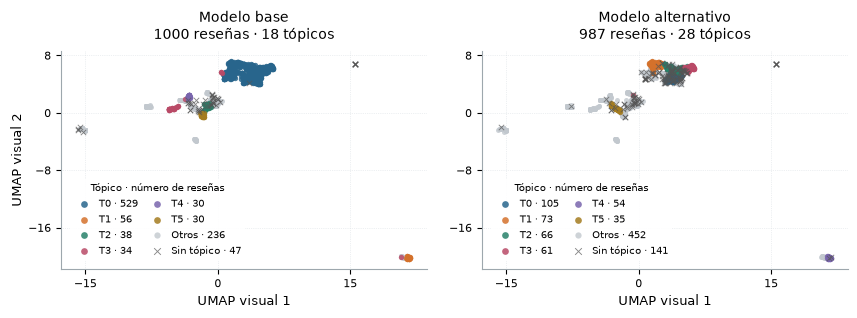

Ajustes UMAP solo para visualización: 0 · agrupamientos nuevos: 0


In [6]:
from importlib.metadata import version
from umap import UMAP

visual_parameters = dict(n_components=2,n_neighbors=15,min_dist=0.0,metric='cosine',random_state=42,n_jobs=1)
visual_ids = inputs['base'].reviews.record_id.tolist()
visual_vectors = inputs['base'].vectors
visual_identity = {'policy':'shared-base-embedding-umap-2d-v1',
 'vectors_sha256':hashlib.sha256(np.ascontiguousarray(visual_vectors).tobytes()).hexdigest(),
 'record_ids_sha256':hashlib.sha256(json.dumps(visual_ids,ensure_ascii=False).encode()).hexdigest(),
 'parameters':visual_parameters,'software':{name:version(name) for name in ['umap-learn','numpy','numba','scikit-learn']}}
visual_key = hashlib.sha256(json.dumps(visual_identity,sort_keys=True).encode()).hexdigest()
visual_dir = NB_ROOT/'sources/agrupamiento-proyeccion-comun'/visual_key
visual_file = visual_dir/'coordinates.csv'
visual_manifest = visual_dir/'manifest.json'
visual_fit_count = 0
if visual_dir.exists():
    saved_visual = json.loads(visual_manifest.read_text())
    assert saved_visual['identity']==visual_identity
    assert saved_visual['coordinates_sha256']==digest(visual_file)
    visual = pd.read_csv(visual_file)
else:
    xy = UMAP(**visual_parameters).fit_transform(visual_vectors.copy())
    visual = pd.DataFrame({'record_id':visual_ids,'visual_x':xy[:,0],'visual_y':xy[:,1]})
    assert np.isfinite(xy).all()
    visual_dir.mkdir(parents=True,exist_ok=False)
    visual.to_csv(visual_file,index=False)
    saved_visual = {'identity':visual_identity,'coordinates_sha256':digest(visual_file),
                    'purpose':'display only, never used to refit clustering','rows':len(visual)}
    visual_manifest.write_text(json.dumps(saved_visual,ensure_ascii=False,indent=2)+'\n')
    visual_fit_count = 1
assert visual.record_id.tolist()==visual_ids and visual.record_id.is_unique
assert np.isfinite(visual[['visual_x','visual_y']].to_numpy()).all()
source('shared_visual_projection',visual_manifest)
source('shared_visual_coordinates',visual_file)

from matplotlib.ticker import MaxNLocator
palette = ['#28658C','#D4712B','#28816A','#B94A67','#7965AD','#A47C20']
map_fig, map_axes = plt.subplots(1,2,figsize=(8.6,3.4),sharex=True,sharey=True)
map_fig.subplots_adjust(left=.07,right=.985,bottom=.16,top=.80,wspace=.15)
map_frames = {}; highlighted = {}
for ax,system in zip(map_axes,SYSTEMS):
    points = frames[system][['record_id','topic_id']].merge(visual,on='record_id',validate='one_to_one')
    assert len(points)==len(frames[system])
    map_frames[system] = points.set_index('record_id')
    noise = points.topic_id.eq(-1)
    sizes = points.loc[~noise].groupby('topic_id').size().rename('size').reset_index().sort_values(['size','topic_id'],ascending=[False,True])
    largest = sizes.head(6).topic_id.tolist();highlighted[system]=[int(t) for t in largest]
    other = ~noise & ~points.topic_id.isin(largest)
    # All reviews stay in the map; only the six largest topics receive individual colors.
    others = ax.scatter(points.loc[other,'visual_x'],points.loc[other,'visual_y'],s=13,c='#C2C8CE',alpha=.8,linewidths=0,label=f'Otros · {int(other.sum())}',zorder=2)
    handles = []
    for topic,color in zip(largest,palette):
        members=points.loc[points.topic_id.eq(topic)]
        handles.append(ax.scatter(members.visual_x,members.visual_y,s=15,c=color,alpha=.85,linewidths=0,label=f'T{topic} · {len(members)}',zorder=3))
    unassigned=ax.scatter(points.loc[noise,'visual_x'],points.loc[noise,'visual_y'],s=15,c='#555555',marker='x',linewidths=.65,alpha=.7,label=f'Sin tópico · {int(noise.sum())}',zorder=4)
    ax.set_title(f"{SYSTEMS[system]}\n{len(points)} reseñas · {len(sizes)} tópicos",fontsize=10,pad=9)
    ax.set_xlabel('UMAP visual 1',fontsize=9,labelpad=3)
    ax.xaxis.set_major_locator(MaxNLocator(4));ax.yaxis.set_major_locator(MaxNLocator(4))
    ax.tick_params(labelsize=8,labelleft=True)
    ax.grid(color='#DCE2E6',linewidth=.5,linestyle=':',zorder=0)
    ax.spines[['top','right']].set_visible(False)
    ax.spines[['bottom','left']].set_color('#9DA7AD')
    ax.legend(handles=handles+[others,unassigned],loc='lower left',bbox_to_anchor=(.01,.015),ncol=2,
              title='Tópico · número de reseñas',title_fontsize=7.5,fontsize=7.5,
              frameon=True,facecolor='white',edgecolor='none',framealpha=.93,
              handletextpad=.4,columnspacing=.8,markerscale=1.25,borderpad=.4)
    tables[system+'-mapa-agrupamiento'] = points
map_axes[0].set_ylabel('UMAP visual 2',fontsize=9,labelpad=3)
common_visual_ids = map_frames['alternative'].index
assert np.array_equal(map_frames['base'].loc[common_visual_ids,['visual_x','visual_y']].to_numpy(),map_frames['alternative'][['visual_x','visual_y']].to_numpy())
figures['agrupamiento-proyeccion-comun'] = map_fig
payloads['proyeccion-visual'] = {'source_manifest':str(visual_manifest.relative_to(REPO)),
 'identity':visual_identity,'coordinates_sha256':digest(visual_file),'visual_umap_fits_this_execution':visual_fit_count,
 'highlighted_topics':highlighted,'color_policy':'six-largest-per-system-rest-gray-local-colors-v1',
 'new_clustering_fits':0,'same_coordinates_for_common_reviews':True,'removed_reviews_omitted':13}
display(map_fig)
plt.close(map_fig)
print('Ajustes UMAP solo para visualización:',visual_fit_count,'· agrupamientos nuevos: 0')


## 5. Antes de interpretar: ¿reprodujimos los resultados del reporte?

Comparamos la corrida nueva contra la original usando IDs de reseña, pertenencia a grupos, sentimiento y palabras clave. ARI compara particiones sin asumir que los números de tópico sean equivalentes: 1 indica la misma partición. Aquí se incluye −1 como una categoría para comprobar reproducción, no para afirmar calidad temática. También distinguimos palabras idénticas de pesos idénticos: pequeñas diferencias numéricas en estos últimos pueden impedir reutilizar una solicitud LLM mediante su hash, aun cuando no cambien las palabras ni los grupos.

In [7]:
reproduction=[]
for system in SYSTEMS:
 old_run=json.loads((OLD/f'{system}-run.json').read_text());old=read_analysis(old_run['representation']['analysis_id'])
 before=pd.DataFrame([asdict(a) for a in old.assignments]).set_index('record_id')
 after=frames[system].set_index('record_id').loc[before.index]
 old_sent=pd.Series({x.record_id:x.model_label for x in old.sentiments})
 exact=before.topic_id.equals(after.topic_id)
 old_keywords={t.topic_id:[(k.term,k.weight) for k in t.keywords] for t in old.topics}
 new_keywords={t.topic_id:[(k.term,k.weight) for k in t.keywords] for t in analyses[system].topics}
 reproduction.append({'system':system,'ari_with_original':adjusted_rand_score(before.topic_id,after.topic_id),'identical_topic_ids':exact,
 'identical_sentiment':bool((old_sent.loc[after.index]==after.model_label).all()),'identical_keywords':old_keywords==new_keywords,
 'same_keyword_terms':all([w[0] for w in old_keywords[t]]==[w[0] for w in new_keywords[t]] for t in old_keywords),
 'max_keyword_weight_delta':max(abs(w[1]-v[1]) for t in old_keywords for w,v in zip(old_keywords[t],new_keywords[t])),
 'new_pipeline_this_execution':system in new_runs,'original_analysis_id':old.manifest.analysis_id,'new_analysis_id':analyses[system].manifest.analysis_id})
reproduction=pd.DataFrame(reproduction)
pair(table(reproduction.loc[reproduction.system.eq('base')].drop(columns=['original_analysis_id','new_analysis_id'])),table(reproduction.loc[reproduction.system.eq('alternative')].drop(columns=['original_analysis_id','new_analysis_id'])))
assert reproduction.ari_with_original.eq(1).all() and reproduction.identical_sentiment.all(), 'La reproducción difiere; analizar antes de sustituir resultados del reporte.'
tables['verificacion-reproduccion']=reproduction

Sistema,ARI vs. original,IDs de tópico idénticos,Sentimiento idéntico,Palabras y pesos idénticos,Mismas palabras,Máxima diferencia de pesos,Pipeline nuevo en esta apertura
base,1,True,True,False,True,5.96046e-08,False
Sistema,ARI vs. original,IDs de tópico idénticos,Sentimiento idéntico,Palabras y pesos idénticos,Mismas palabras,Máxima diferencia de pesos,Pipeline nuevo en esta apertura
alternative,1,True,True,False,True,2.98023e-07,False


## 6. Tamaños y cobertura, lado a lado

`−1` significa sin asignación a un grupo, no irrelevancia. No contamos −1 como tópico. Cada porcentaje usa la cantidad de reseñas que entró a su sistema. La altura de la barra muestra cuántas reseñas quedaron en cada tópico; las posiciones de ambas columnas **no emparejan temas**.

Sistema,Reseñas,Tópicos,Sin tópico,Sin tópico (%),Grupo mayor,Grupo mayor (%)
base,1000,18,47,4.7,529,52.9
Sistema,Reseñas,Tópicos,Sin tópico,Sin tópico (%),Grupo mayor,Grupo mayor (%)
alternative,987,28,141,14.2857,105,10.6383


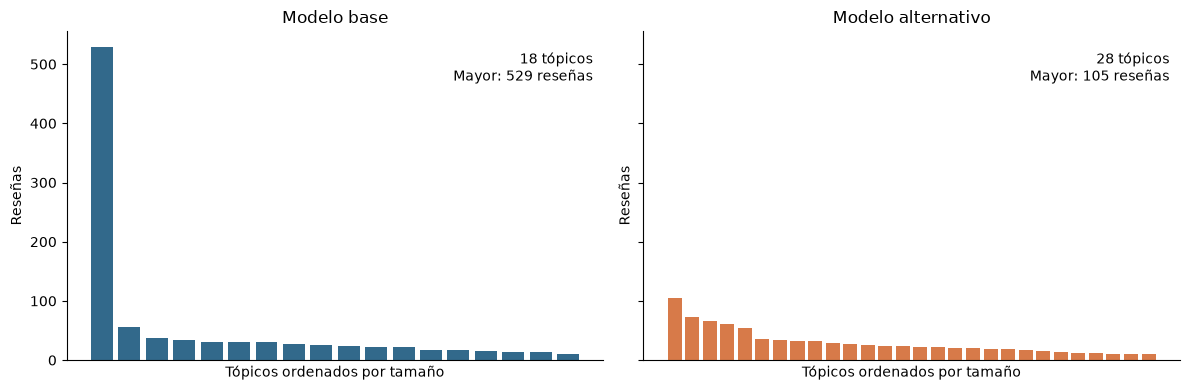

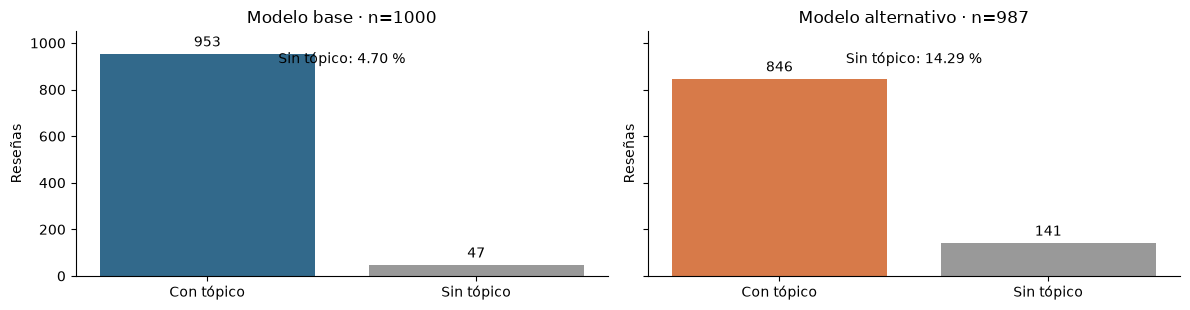

In [8]:
summary=[]
for system,frame in frames.items():
 sizes=frame.loc[frame.topic_id.ge(0)].groupby('topic_id').size().sort_values(ascending=False)
 summary.append({'system':system,'rows':len(frame),'topics':len(sizes),'unassigned':int(frame.topic_id.eq(-1).sum()),
 'unassigned_pct':float(frame.topic_id.eq(-1).mean()*100),'largest':int(sizes.max()),'largest_pct':float(sizes.max()/len(frame)*100)})
summary=pd.DataFrame(summary);tables['resumen-agrupamiento']=summary
pair(table(summary.loc[summary.system.eq('base')]),table(summary.loc[summary.system.eq('alternative')]))
fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=True)
for ax,(system,color) in zip(axes,[('base',BLUE),('alternative',ORANGE)]):
 sizes=topic_tables[system].loc[lambda d:d.topic_id.ge(0)].sort_values(['size','topic_id'],ascending=[False,True])
 ax.bar(np.arange(len(sizes)),sizes['size'],color=color)
 ax.set(title=SYSTEMS[system],xlabel='Tópicos ordenados por tamaño',ylabel='Reseñas',xticks=[])
 ax.text(.98,.94,f"{len(sizes)} tópicos\nMayor: {sizes['size'].max()} reseñas",transform=ax.transAxes,ha='right',va='top')
fig.tight_layout();plt.show();figures['tamano-topicos-dos-columnas']=fig
fig,axes=plt.subplots(1,2,figsize=(12,3.2),sharey=True)
for ax,row,color in zip(axes,summary.itertuples(),[BLUE,ORANGE]):
 bars=ax.bar(['Con tópico','Sin tópico'],[row.rows-row.unassigned,row.unassigned],color=[color,'#999'])
 ax.bar_label(bars,padding=3);ax.set(title=f'{SYSTEMS[row.system]} · n={row.rows}',ylabel='Reseñas',ylim=(0,1050))
 ax.text(.5,.87,f'Sin tópico: {row.unassigned_pct:.2f} %',transform=ax.transAxes,ha='center')
fig.tight_layout();plt.show();figures['cobertura-dos-columnas']=fig

## 7. Separar dos efectos: quitar filas y volver a agrupar

Un control descriptivo responde: **¿qué quedaría si solo quitáramos los 13 comentarios, conservando los tópicos base?** No es otro modelo entrenado: tomamos las asignaciones base de los 987 IDs conservados. Lo comparamos con los resultados de reajustar sobre esos mismos 987 textos.

Esto distingue el efecto aritmético de la exclusión del cambio de partición. No separa cuánto corresponde a UMAP y cuánto a HDBSCAN, ni demuestra que el filtro mejore la semántica. Es una comparación de esta muestra y esta configuración, no una prueba de estabilidad entre semillas.

In [9]:
common=frames['base'][['record_id','topic_id','model_text','platform','model_label']].rename(columns={'topic_id':'base_topic','model_label':'base_sentiment'}).merge(
 frames['alternative'][['record_id','topic_id','model_label']].rename(columns={'topic_id':'alternative_topic','model_label':'alternative_sentiment'}),on='record_id',validate='one_to_one')
assert len(common)==987
removed_topics=removed.merge(frames['base'][['record_id','topic_id','model_label']],on='record_id',validate='one_to_one')
base_membership=common.base_topic
control={'rows':len(common),'topics':int(base_membership.loc[base_membership.ge(0)].nunique()),'unassigned':int(base_membership.eq(-1).sum()),'largest':int(base_membership.loc[base_membership.ge(0)].value_counts().max())}
alt_row=summary.loc[summary.system.eq('alternative')].iloc[0]
pair('<p><b>Control: base restringida a los 987 conservados, sin reajustar</b></p>'+table(pd.DataFrame([control])),
 '<p><b>Alternativa: nuevo ajuste sobre los mismos 987 textos</b></p>'+table(pd.DataFrame([alt_row[['rows','topics','unassigned','largest']].to_dict()])))
origin=removed_topics.groupby(['topic_id','human_label']).size().rename('retiradas').reset_index()
pair('<p>¿En qué grupos estaban los 13 retirados?</p>'+table(origin),'<p>Los 13 ya no aparecen. El cambio de los restantes se estudia por sus identificadores en las siguientes figuras.</p>')
tables['retirados-grupo-base']=removed_topics[['record_id','model_text','platform','topic_id','model_label','margin','human_label']]
tables['control-sin-reajuste']=pd.DataFrame([control]);tables['asignaciones-comunes']=common
pair(f'<p>Excluir filas sin reajustar deja el grupo mayor en <b>{control["largest"]}</b> reseñas y conserva <b>{control["unassigned"]}</b> sin tópico.</p>', f'<p>El reajuste produce un grupo mayor de <b>{int(alt_row.largest)}</b> y <b>{int(alt_row.unassigned)}</b> sin tópico. Esta diferencia no se explica por restar las 13 filas: cambia la partición de las conservadas.</p>')

Reseñas,Tópicos,Sin tópico,Grupo mayor
987,18,47,518
Reseñas,Tópicos,Sin tópico,Grupo mayor
987,28,141,105


Tópico,Revisión humana,Retiradas
0,irrelevant,8
0,relevant,3
10,irrelevant,2


## 8. Qué reseñas pierden o ganan asignación a un grupo

Aquí no comparamos números de tópico. Preguntamos si cada uno de los 987 comentarios comunes tiene algún grupo antes y después. Así evitamos confundir una renumeración con un cambio real. Los 13 retirados no están en este denominador.

In [10]:
transition=pd.crosstab(common.base_topic.ge(0).map({True:'Con tópico',False:'Sin tópico'}),common.alternative_topic.ge(0).map({True:'Con tópico',False:'Sin tópico'})).reindex(index=['Con tópico','Sin tópico'],columns=['Con tópico','Sin tópico'],fill_value=0)
assert int(transition.to_numpy().sum())==987
lost=common.loc[common.base_topic.ge(0)&common.alternative_topic.eq(-1)]
gained=common.loc[common.base_topic.eq(-1)&common.alternative_topic.ge(0)]
pair('<p>Estado base de los mismos 987 textos.</p>'+table(transition.reset_index().rename(columns={'base_topic':'Estado base'})),
 f'<p><b>{len(lost)}</b> pasan de tener tópico a quedar sin asignar.</p><p><b>{len(gained)}</b> pasan de no tener tópico a recibir uno.</p><p>La diferencia neta es <b>{len(lost)-len(gained)}</b> reseñas adicionales sin tópico, sobre el conjunto común.</p>')
ari_all=adjusted_rand_score(common.base_topic,common.alternative_topic)
both=common.loc[common.base_topic.ge(0)&common.alternative_topic.ge(0)]
ari_assigned=adjusted_rand_score(both.base_topic,both.alternative_topic)
payloads['transiciones']={'common_rows':987,'became_unassigned':len(lost),'became_assigned':len(gained),'assigned_both_rows':len(both),'ari_including_minus1_as_group':ari_all,'ari_assigned_intersection':ari_assigned,'note':'ARI describes agreement, not thematic quality; assigned intersection is a different subset.'}
tables['transiciones-cobertura']=transition.reset_index()
pair(f'<p>ARI en los 987 comunes, incluyendo −1 como una categoría: <b>{ari_all:.4f}</b>.</p>',f'<p>ARI en los {len(both)} asignados en ambos sistemas: <b>{ari_assigned:.4f}</b>.</p><p>Excluir los no asignados cambia la población comparada.</p>')

alternative_topic,Estado base,Con tópico,Sin tópico
,Con tópico,827,113
,Sin tópico,19,28


## 9. Seguir el grupo mayor: ¿a dónde fueron sus reseñas?

Seleccionamos el grupo base de mayor tamaño, no el que produzca el ejemplo más llamativo. A la izquierda vemos su composición original y las filas retiradas. A la derecha seguimos **exactamente sus miembros conservados** hacia los tópicos alternativos o hacia −1. Es una distribución por IDs, no una comparación de nombres o de posiciones en un dibujo.

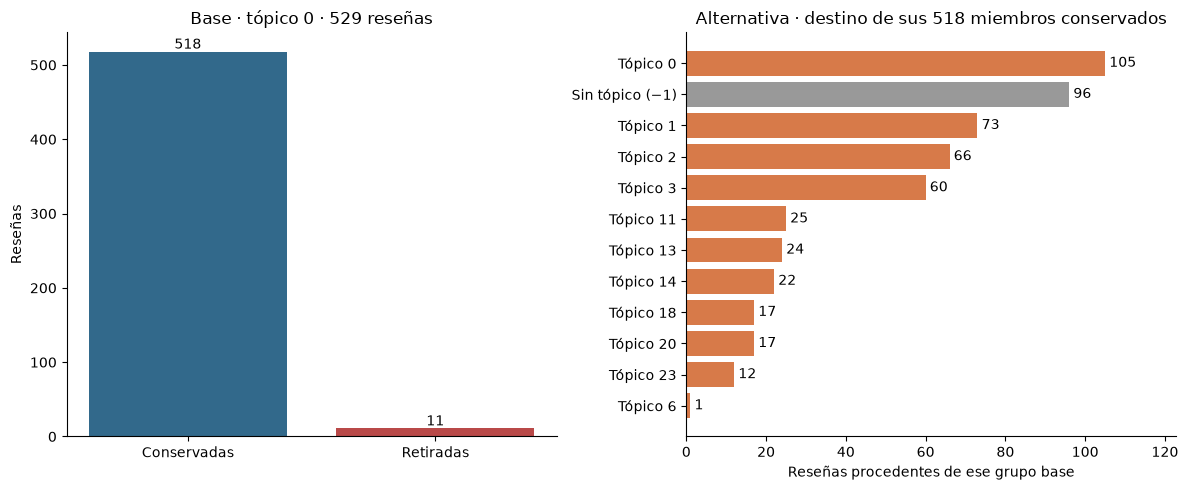

Tópico alternativo,Reseñas,Palabras clave
0,105,"app queda, abrir app, app, abre, pantalla, pantalla azul"
-1,96,"entrar aplicación, netkey no, netkey, pagar, key, servidor"
1,73,"tarda mucho, no deja, tener esperar, abre tarda, 15 días, cualquier hora"
2,66,"app banco, app tarda, aplicación banco, banca móvil, bancaria, banca"
3,60,"móvil banamex, banamex app, app banamex, aplicación banamex, banamex no, app no"
11,25,"abrir aplicacion, abre app, abrir aplicación, abre aplicación, aplicación no, porque aplicación"
13,24,"muchas fallas, tiene fallas, fallas demás, hay fallas, fallas capacidad, fallas siempre"
14,22,"nada amigable, ninguna seguridad, mucho no, hay ninguna, mala seguridad, no intuitiva"
18,17,"falla mucho, bastante traba, traba poco, mucho falla, traba simplemente, traba tratar"
20,17,"tarjeta digital, tarjeta, no tarjeta, tarjeta no, apps, bloquear"


In [11]:
largest_id=int(topic_tables['base'].loc[lambda d:d.topic_id.ge(0)].iloc[0].topic_id)
initial_size=int(frames['base'].topic_id.eq(largest_id).sum())
removed_from_largest=int(removed_topics.topic_id.eq(largest_id).sum())
follow=common.loc[common.base_topic.eq(largest_id)]
dest=follow.groupby('alternative_topic').size().rename('rows').reset_index().sort_values(['rows','alternative_topic'],ascending=[False,True])
assert int(dest.rows.sum())+removed_from_largest==initial_size
fig,axes=plt.subplots(1,2,figsize=(12,5))
axes[0].bar(['Conservadas','Retiradas'],[len(follow),removed_from_largest],color=[BLUE,RED]);axes[0].set(title=f'Base · tópico {largest_id} · {initial_size} reseñas',ylabel='Reseñas')
for i,n in enumerate([len(follow),removed_from_largest]):axes[0].text(i,n+4,str(n),ha='center')
labels=['Sin tópico (−1)' if t==-1 else f'Tópico {t}' for t in dest.alternative_topic]
bars=axes[1].barh(labels,dest.rows,color=['#999' if t==-1 else ORANGE for t in dest.alternative_topic]);axes[1].invert_yaxis();axes[1].bar_label(bars,padding=3)
axes[1].set(title=f'Alternativa · destino de sus {len(follow)} miembros conservados',xlabel='Reseñas procedentes de ese grupo base');axes[1].set_xlim(0,dest.rows.max()*1.17)
fig.tight_layout();plt.show();figures['destino-del-grupo-mayor']=fig
keywords=topic_tables['alternative'].set_index('topic_id').keywords
flow=dest.assign(keywords=dest.alternative_topic.map(keywords));tables['destino-grupo-mayor']=flow
non_noise=int(dest.alternative_topic.ge(0).sum());noise=int(dest.loc[dest.alternative_topic.eq(-1),'rows'].sum())
pair(f'<p>De las <b>{initial_size}</b> reseñas originales, el filtro retira <b>{removed_from_largest}</b> y deja <b>{len(follow)}</b>.</p>',f'<p>Esas {len(follow)} reseñas se reparten entre <b>{non_noise} tópicos alternativos</b>; <b>{noise}</b> quedan sin asignar. No son {non_noise} funcionalidades validadas: son destinos del agrupamiento.</p>')
pair('<p>Palabras del grupo base:</p><p>'+e(topic_tables['base'].set_index('topic_id').loc[largest_id,'keywords'])+'</p><p>Todos los destinos de la derecha proceden de este grupo.</p>',table(flow))

## 10. Ver todos los cruces, no solo el grupo mayor

Filas: tópicos base. Columnas: tópicos alternativos. Cada celda indica cuántas reseñas comunes comparten ambas asignaciones. Un grupo base repartido entre varias columnas se fragmentó; una columna alimentada por varias filas reúne miembros de diferentes grupos originales. Los números de tópico son locales: **la diagonal no significa aciertos**.

Se incluye −1 para conservar los 987 textos. El color usa escala logarítmica solo para hacer visibles flujos pequeños; los números impresos son conteos reales.

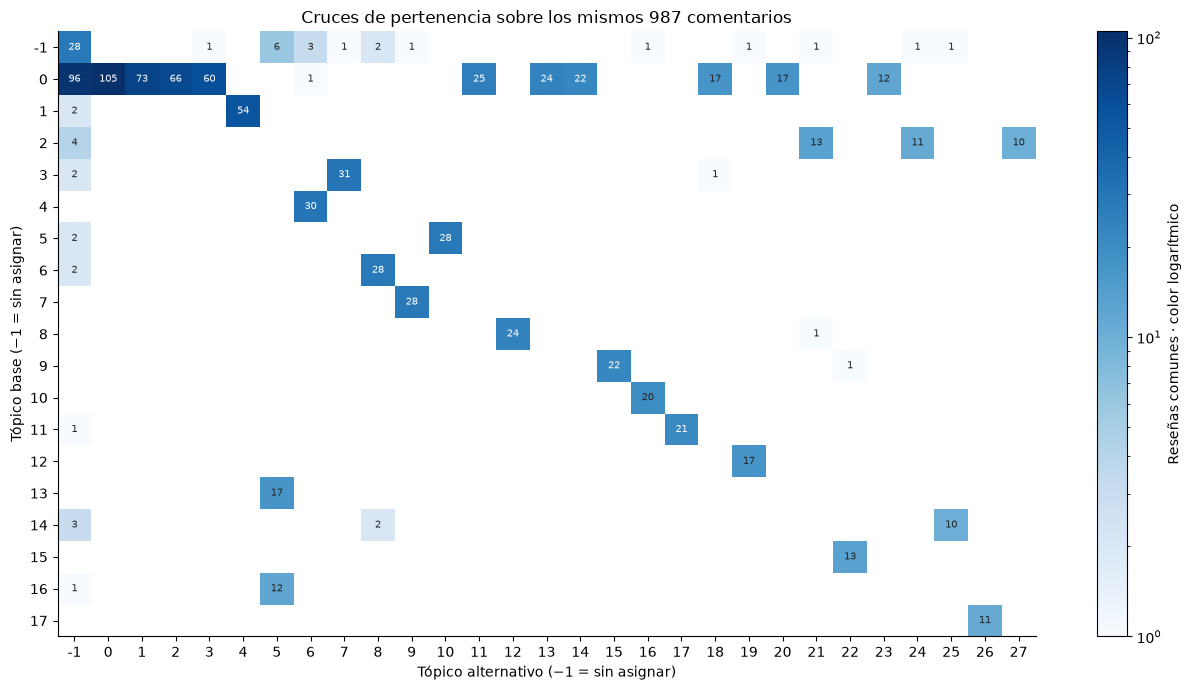

In [12]:
from matplotlib.colors import LogNorm
cross=pd.crosstab(common.base_topic,common.alternative_topic)
assert cross.to_numpy().sum()==987
fig,ax=plt.subplots(figsize=(13,7))
im=ax.imshow(np.ma.masked_equal(cross.to_numpy(),0),norm=LogNorm(vmin=1,vmax=cross.to_numpy().max()),cmap='Blues',aspect='auto')
ax.set(xticks=range(len(cross.columns)),xticklabels=[str(t) for t in cross.columns],yticks=range(len(cross.index)),yticklabels=[str(t) for t in cross.index],xlabel='Tópico alternativo (−1 = sin asignar)',ylabel='Tópico base (−1 = sin asignar)',title='Cruces de pertenencia sobre los mismos 987 comentarios')
for i in range(len(cross.index)):
 for j in range(len(cross.columns)):
  n=int(cross.iloc[i,j])
  if n:ax.text(j,i,str(n),ha='center',va='center',fontsize=7,color='white' if n>20 else '#222')
fig.colorbar(im,ax=ax,label='Reseñas comunes · color logarítmico');fig.tight_layout();plt.show();figures['cruce-todos-los-grupos']=fig
tables['cruce-todos-los-grupos']=cross.reset_index()

## 11. Leer comentarios de las redistribuciones principales

Tomamos los tres destinos con más miembros del grupo mayor base, incluyendo −1 si corresponde. En cada destino mostramos hasta dos textos distintos, elegidos por hash SHA-256 con semilla 42. El texto es el mismo a ambos lados: lo que cambia es su agrupamiento. Esta regla limita la selección oportunista de ejemplos; no convierte seis comentarios en una evaluación global.

In [13]:
from apoyo_validacion import ranked_sample
examples=[]
for destination in dest.head(3).alternative_topic:
 subset=follow.loc[follow.alternative_topic.eq(destination)]
 selected=ranked_sample(subset,2,f'removals-flow-v1:42:{largest_id}:{destination}',distinct_text=True)
 for row in selected.itertuples():
  body='<p style="white-space:pre-wrap">'+e(row.model_text)+'</p><small>'+e(row.record_id)+'</small>'
  pair(f'<p>Tópico base <b>{row.base_topic}</b></p>'+body,f'<p>Destino: <b>{"sin asignar (−1)" if row.alternative_topic==-1 else "tópico "+str(row.alternative_topic)}</b></p>'+body)
  examples.append({'record_id':row.record_id,'text':row.model_text,'base_topic':int(row.base_topic),'alternative_topic':int(row.alternative_topic)})
payloads['ejemplos-transiciones']=examples

## 12. Completar el recorrido: palabras clave, sentimiento e interpretación

El agrupamiento se construye sin usar las predicciones de sentimiento. Después, la representación ayuda a leer cada grupo y Robertuito aporta una etiqueta por reseña. Ambas señales se consultan juntas. Mostramos todos los tópicos y las distribuciones de sentimiento; los ID siguen siendo locales.

Para el LLM verificamos las solicitudes de esta corrida contra las respuestas guardadas. Reutilizamos las idénticas; las faltantes se ejecutan una sola vez cuando se habilita el pipeline. La corrida nueva necesitó 16 solicitudes por pequeñas diferencias de pesos y reutilizó 30. Al volver a abrir la libreta se leen las respuestas guardadas, sin cargos. Las categorías nuevas se comparan con las originales, sin reemplazarlas en el reporte.

Tópico,size,Palabras clave,Categoría LLM,Nombre LLM
0,529,"app, aplicación, no abre, tarjeta, banamex, abrir",mixed,Problemas de acceso y visualización de movimientos en la aplicación móvil
1,56,"excelentes excelente, perfeccion excelente, excelente siempre, siempre excelentes, tal perfeccion, perfeccion",unclear,Calidad general de la aplicación
-1,47,"buena aplicación, aplicación ok, recomiendo, muy práctica, ok app, mejorado",No se interpreta −1,No se interpreta −1
2,38,"excelente aplicación, buena aplicación, aplicación muy, accesible, operatividad app, seguridad excelente",mixed,Seguridad y facilidad de uso de la aplicación
3,34,"todo bien, excelente bien, bien funciona, gracias mejorarla, mejorado todo, funciona muy",unclear,Funcionamiento general de la aplicación
4,30,"excelente servicio, servicio excelente, servicio buen, buen servicio, servicio muy, muy buenos",mixed,Calidad del servicio y atención al cliente
5,30,"fácil usar, usar fácil, útil sencilla, muy fácil, fácil rápida, fácil muy",single_feature,Facilidad de uso de la aplicación
6,30,"app buena, buena app, app excelente, excelente app, encanta app, ya mejoró",single_feature,Mejoras en la velocidad de apertura y rendimiento general de la aplicación
7,28,"muy buena, muy bueno, buena muy, buena buena, buena excelente, buena gusta",unclear,Calidad general de la aplicación
8,25,"excelente aplicación, excelente aplicacion, aplicación buena, buena aplicación, aplicación excelente, maravillosa aplicación",unclear,Valoración positiva general de la aplicación


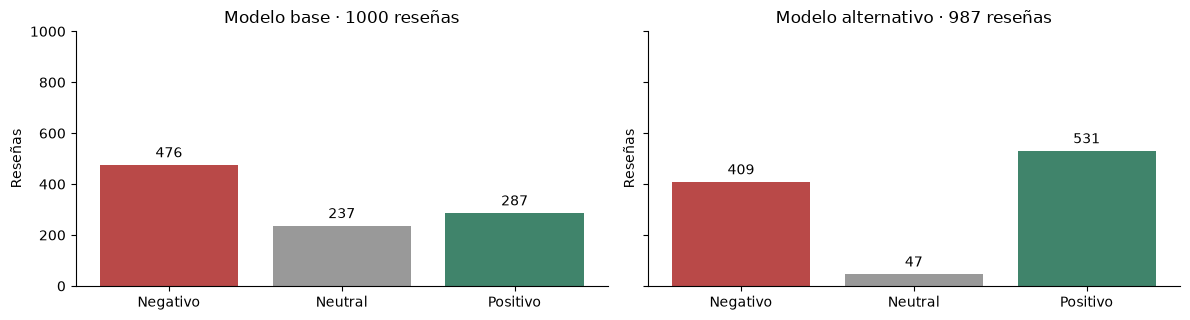

Tópico,Categoría original,Categoría LLM,Cambió categoría
0,mixed,mixed,False
1,unclear,unclear,False
2,mixed,mixed,False
3,unclear,unclear,False
4,mixed,mixed,False
5,single_feature,single_feature,False
6,single_feature,single_feature,False
7,unclear,unclear,False
8,unclear,unclear,False
9,mixed,mixed,False


Solicitudes nuevas en la corrida guardada: 16
Solicitudes nuevas al ejecutar ahora la libreta: 0


In [14]:
LABELS=['negative','neutral','positive'];llm_rows=[]
llm_config_path=REPO/'config/analysis/interpretation.toml'
llm_config=load_config(llm_config_path)
llm_receipt_path=RUN/'interpretation-run.json'
new_llm_requests=0
if llm_receipt_path.exists():
 llm_receipt=json.loads(llm_receipt_path.read_text())
 assert llm_receipt['state']=='completed', 'Inspeccionar la interpretación incompleta; no se reintenta automáticamente.'
else:
 if not ALLOW_RUN:raise RuntimeError('Falta completar la interpretación de esta corrida. Habilita el pipeline explícitamente.')
 llm_receipt={'state':'running','batches':[],'final_analyses':{}}
 def save_llm():
  tmp=llm_receipt_path.with_suffix('.tmp');tmp.write_text(json.dumps(llm_receipt,indent=2)+'\n');tmp.replace(llm_receipt_path)
 save_llm()
 for system,a in analyses.items():
  ids=sorted(t.topic_id for t in a.topics if t.topic_id>=0)
  for start in range(0,len(ids),llm_config.max_topics):
   parent=llm_receipt['final_analyses'].get(system,a.manifest.analysis_id)
   selected=ids[start:start+llm_config.max_topics]
   print(f'Interpretación {system}: tópicos {selected[0]}–{selected[-1]}',flush=True)
   result=interpret(parent,selected,llm_config_path,live=True)
   llm_receipt['batches'].append({'system':system,'result':result})
   if result.get('analysis_id'):llm_receipt['final_analyses'][system]=result['analysis_id']
   save_llm()
   if result['state']!='completed':raise RuntimeError('Interpretación requiere inspección; no se reintenta.')
   new_llm_requests+=result['counts']['provider_attempts']
 llm_receipt['state']='completed';save_llm()
source('interpretation_run',llm_receipt_path)
for system,aid in llm_receipt['final_analyses'].items():
 saved=read_analysis(aid)
 source(system+'_interpreted_analysis',data_root()/'analyses'/aid/'manifest.json')
 for record in saved.interpretations:
  assert record['status']=='completed'
  result=record['result']
  llm_rows.append({'system':system,'topic_id':record['topic_id'],'assessment':result['assessment'],'name':result['name'],
   'proposed_feature':result['proposed_feature'],'attempt_id':record['attempt_id'],'reused':record['reuse_origin'] is not None,
   'analysis_id':aid,'request_fingerprint':record['request_fingerprint'],'new_cost_usd':record['provider']['usage'].get('cost',0) if record['reuse_origin'] is None else 0})
 part=pd.DataFrame([r for r in llm_rows if r['system']==system])
 tables[system+'-topicos-palabras-llm']=topic_tables[system].merge(part[['topic_id','assessment','name']],on='topic_id',how='left')
pair(table(tables['base-topicos-palabras-llm'].fillna('No se interpreta −1')),table(tables['alternative-topicos-palabras-llm'].fillna('No se interpreta −1')))
fig,axes=plt.subplots(1,2,figsize=(12,3.3),sharey=True)
for ax,(system,frame) in zip(axes,frames.items()):
 values=frame.model_label.value_counts().reindex(LABELS,fill_value=0)
 bars=ax.bar(['Negativo','Neutral','Positivo'],values,color=[RED,'#999','#40846b']);ax.bar_label(bars,padding=3)
 ax.set(title=SYSTEMS[system]+f' · {len(frame)} reseñas',ylim=(0,1000),ylabel='Reseñas')
fig.tight_layout();plt.show();figures['sentimiento-dos-columnas']=fig
changed=int(common.base_sentiment.ne(common.alternative_sentiment).sum())
pair('<p>Robertuito original.</p>',f'<p>Robertuito adaptado. Sobre los 987 textos comunes, <b>{changed}</b> etiquetas difieren. Sin referencia humana independiente, no las llamamos correcciones.</p>')
llm_table=pd.DataFrame(llm_rows);tables['interpretaciones']=llm_table
assert len(llm_rows)==46
old_snapshot_path=NB_ROOT/'sources/interpretacion-seccion-4/20261107T174441Z/evidencia.json'
source('original_llm_snapshot',old_snapshot_path)
old_snapshot=json.loads(old_snapshot_path.read_text())
previous=pd.DataFrame([{'system':x['system'],'topic_id':x['topic_id'],'original_assessment':x['record']['result']['assessment']} for x in old_snapshot['topics']])
llm_comparison=llm_table.merge(previous,on=['system','topic_id'],validate='one_to_one')
llm_comparison['changed_category']=llm_comparison.assessment.ne(llm_comparison.original_assessment)
tables['comparacion-llm-con-reporte']=llm_comparison
pair(table(llm_comparison.loc[llm_comparison.system.eq('base'),['topic_id','original_assessment','assessment','changed_category']]),table(llm_comparison.loc[llm_comparison.system.eq('alternative'),['topic_id','original_assessment','assessment','changed_category']]),'Comprobación: categorías originales frente a esta corrida')
print('Solicitudes nuevas en la corrida guardada:',sum(b['result']['counts']['provider_attempts'] for b in llm_receipt['batches']))
print('Solicitudes nuevas al ejecutar ahora la libreta:',new_llm_requests)
category_changes=int(llm_comparison.changed_category.sum())
pair('<p>Las interpretaciones originales del reporte se conservan.</p>',f'<p>En esta corrida cambiaron <b>{category_changes}</b> categorías respecto del reporte. No atribuimos el cambio a los pequeños decimales: también puede intervenir la variabilidad de las respuestas del proveedor. No es una prueba sistemática de estabilidad del LLM.</p>')


## 13. Qué podemos explicar con esta comparación

- Los 13 textos y la revisión humana permiten distinguir diez exclusiones pertinentes y tres pérdidas de información relevante. No miden los errores entre todos los comentarios conservados.
- El control sin reajuste muestra cuánto cambia la cobertura por quitar esas filas; la comparación con el reajuste muestra la redistribución adicional de los mismos 987 textos.
- Los cruces por ID permiten describir fragmentación, agrupaciones y cambios de asignación sin confundir números de tópico. ARI resume acuerdo, no calidad.
- Los ejemplos muestran asuntos plausibles y sus límites. Más tópicos, menos concentración o más `single_feature` no son pruebas de mejora semántica.
- La corrida reproduce una configuración y una muestra. No separa UMAP de HDBSCAN ni prueba estabilidad en otras semillas, muestras o periodos. El sentimiento adaptado no causa cambios en el agrupamiento.

Los resultados originales del artículo no se reemplazan automáticamente. Esta libreta y sus exportaciones sirven para estudiar qué explicación o figura conviene incorporar después.

In [15]:
payloads['ejecucion']={'schema_version':'voc-stepwise-comparison-v1','original_protocol_id':original['protocol_id'],'replication_protocol_id':protocol['protocol_id'],
 'new_pipelines_this_execution':new_runs,'saved_topic_fits':2,'saved_sentiment_inference_rows':1987,'saved_pipelines':[{'system':s,'run_id':runs[s]['run_id'],'analysis_id':analyses[s].manifest.analysis_id,'zenml_run_id':producer.load_run(runs[s]['run_id'])['zenml_run_id']} for s in SYSTEMS],
 'topic_fits_this_execution':len(new_runs),'sentiment_inference_rows_this_execution':sum(len(frames[s]) for s in new_runs),
 'embedding_vectors_reused':True,'umap_cache_hits':{s:red.reused for s,red in reductions.items()},
 'provider_requests_this_execution':new_llm_requests,'provider_requests_saved_run':sum(b['result']['counts']['provider_attempts'] for b in llm_receipt['batches']),'reused_llm_topics':int(llm_table.reused.sum()),'provider_cost_usd_saved_run':float(llm_table.new_cost_usd.sum()),'human_review_source':'existing review, not new annotations',
 'protected_original_protocol_sha256':digest(OLD/'protocol.json')}
for system,frame in frames.items():tables[system+'-asignaciones']=frame[['record_id','platform','model_text','topic_id','model_label']]
from importlib.metadata import version
stamp=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
out=NB_ROOT/'exports/pipeline-base-alternativa-paso-a-paso'/stamp;out.mkdir(parents=True,exist_ok=False)
for name,fig in figures.items():
 for ext in ['png','pdf']:fig.savefig(out/f'{name}.{ext}',dpi=180,bbox_inches='tight',facecolor='white')
figures['agrupamiento-proyeccion-comun'].savefig(out/'agrupamiento-proyeccion-comun.svg',facecolor='white')
for name,df in tables.items():df.to_csv(out/f'{name}.csv',index=False)
for name,data in payloads.items():(out/f'{name}.json').write_text(json.dumps(data,ensure_ascii=False,indent=2,allow_nan=False)+'\n')
nb_path=NB_ROOT/'pipeline-base-alternativa-paso-a-paso.ipynb';notebook=json.loads(nb_path.read_text())
manifest={'notebook':nb_path.name,'created_at':stamp,'cell_sources_sha256':hashlib.sha256('\n'.join(''.join(c['source']) for c in notebook['cells']).encode()).hexdigest(),
 'sources':sources,'files':{p.name:digest(p) for p in out.iterdir()},'software':{p:version(p) for p in ['numpy','pandas','scikit-learn','umap-learn','hdbscan','bertopic','torch']},
 'model_fits_this_execution':len(new_runs),'visual_umap_fits_this_execution':visual_fit_count,'provider_requests':new_llm_requests,'original_evidence_overwritten':False}
(out/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2)+'\n')
(out.parent/'latest.json').write_text(json.dumps({'directory':str(out.relative_to(NB_ROOT)),'manifest_sha256':digest(out/'manifest.json')},indent=2)+'\n')
print('Evidencia exportada:',out)
print('Nuevos pipelines en esta ejecución:',new_runs,'· solicitudes LLM nuevas:',new_llm_requests)

Evidencia exportada: /workspace/vaults/sonar/code/repos/voc-difusion/reports/difusion/exports/pipeline-base-alternativa-paso-a-paso/20261107T204440472523Z
Nuevos pipelines en esta ejecución: [] · solicitudes LLM nuevas: 0
